**Cell 1: setup**

In [22]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # so we can import from src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.load_data import load_raw_data
from src.config import TARGET

df = load_raw_data()
df.shape

(2930, 82)

**Cell 2: target numbers**

In [23]:
y = df[TARGET]
print(y.describe())
print("Skewness:", round(y.skew(), 2))
print("Skewness of log price:", round(np.log1p(y).skew(), 2))
print("90th percentile:", y.quantile(0.90))
print("Houses at or above it:", (y >= y.quantile(0.90)).sum())

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64
Skewness: 1.74
Skewness of log price: -0.01
90th percentile: 281241.69999999995
Houses at or above it: 293


**Cell 3: plots**

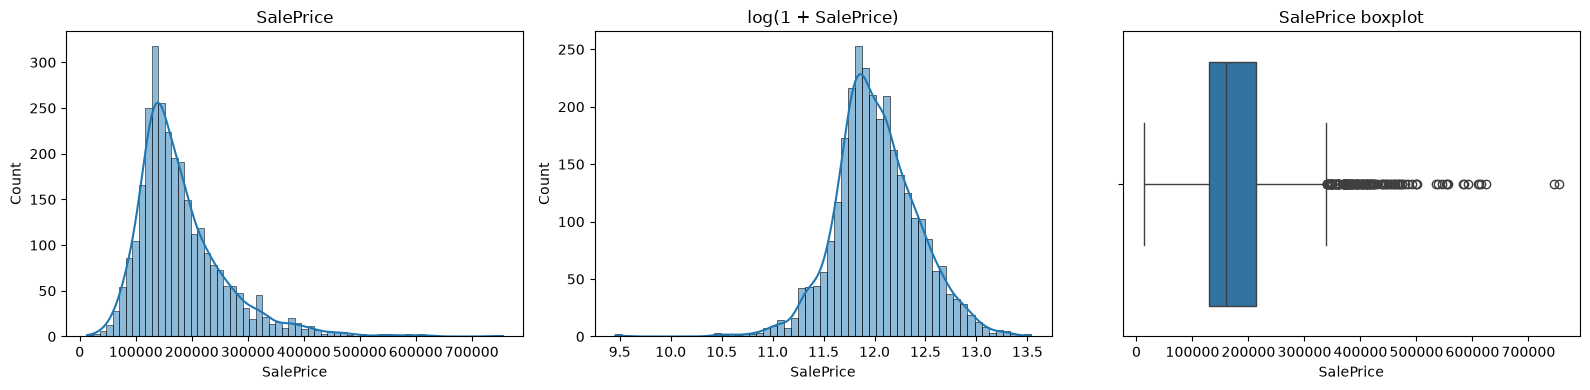

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(y, kde=True, ax=axes[0]);            axes[0].set_title("SalePrice")
sns.histplot(np.log1p(y), kde=True, ax=axes[1]);  axes[1].set_title("log(1 + SalePrice)")
sns.boxplot(x=y, ax=axes[2]);                     axes[2].set_title("SalePrice boxplot")
plt.tight_layout()
plt.show()

## Findings:
**Graph 1:**
1. Distribution Highly Positively Skewed.
2. Most of the houses prices are concentrated from 1 lakh to 2 lakh
3. Some houses has relatively higher prices which is makeing the right tail long.

**Graph 2:**
1. After log1p Transformation the distribution is more symmetric then before.

**Graph 3:**
1. Distribution has high value observations.
2. House Prices of some observation very high.

**Cell 4: Most Expensive and Most Cheap Houses**

In [25]:
cols = [TARGET, "Gr Liv Area", "Overall Qual", "Neighborhood", "Sale Condition"]
display(df.nlargest(5, TARGET)[cols])
display(df.nsmallest(5, TARGET)[cols])

,SalePrice,Gr Liv Area,Overall Qual,Neighborhood,Sale Condition
1767,755000,4316,10,NoRidge,Normal
1760,745000,4476,10,NoRidge,Abnorml
2445,625000,3627,10,NoRidge,Normal
1063,615000,2470,10,NridgHt,Normal
44,611657,2364,9,NridgHt,Partial


,SalePrice,Gr Liv Area,Overall Qual,Neighborhood,Sale Condition
181,12789,832,2,OldTown,Abnorml
1553,13100,733,1,IDOTRR,Abnorml
726,34900,720,4,IDOTRR,Abnorml
2843,35000,498,2,Edwards,Normal
2880,35311,480,2,IDOTRR,Abnorml


## Findings: Target

1. Effect of Extreme Values

**Finding:** SalePrice is right-skewed (skewness 1.74), and the mean is higher than the median.

**Evidence:** After log(1 + price), skewness drops to -0.01.

**Decision:** We will train on log(1 + SalePrice) and convert predictions back with expm1.

2. Model Performance

**Hypothesis (to test in Phase 7):** Training on log(1 + SalePrice) gives lower percentage error than training on raw SalePrice.

**How we will test it:** Train the same model twice (raw target and log target). Compare both on the original price scale using MdAPE, our main metric from the business document.

**Decision for now:** Use the log target as the default. Change it only if the test shows raw is better.

3. potential high-price outliers.

**Finding:** SalePrice contains several potential high-price outliers.

**Evidence:** values above 339,500, total 137 houses.

**Decision:** we will not directly treat/remove them as outliers because in phase 1 we have decided to do Expensive house analysis.

4. Most Expensive and cheapest houses analaysis

**Finding & Evidence:** House with the highest Gr Liv Area(4476) sold at lower price(745000) then the most expensive house sold(755000) despite its Gr Liv Area(4316) is less then that house, point to be noted: the sales condition of this house is Abnorml. In the Cheapest house list 4 out of 5 are Abnorml.

**Decision:** Prices of the houses with sales condition "Abnorml" can be "noisy", this is an Evidence for our assumption 1 but not a proof be will check it later.


**Cell 5: Sale Condition and price**

In [26]:
print(df["Sale Condition"].value_counts())
print()
print(df.groupby("Sale Condition")[TARGET].agg(["count", "median", "mean"]).round(0))
print()
# EDA only. Do NOT use price_per_sqft as a model feature (it is built from the target = leakage).
df["price_per_sqft"] = df[TARGET] / df["Gr Liv Area"]
print(df.groupby("Sale Condition")["price_per_sqft"].median().round(1))

mid_quality = df[df["Overall Qual"].between(5, 7)]
print(mid_quality.groupby("Sale Condition")[TARGET].agg(["count", "median"]))

Sale Condition
Normal     2413
Partial     245
Abnorml     190
Family       46
Alloca       24
AdjLand      12
Name: count, dtype: int64

                count    median      mean
Sale Condition                           
Abnorml           190  129450.0  140396.0
AdjLand            12  110000.0  108917.0
Alloca             24  149617.0  161844.0
Family             46  144400.0  157489.0
Normal           2413  159000.0  175568.0
Partial           245  250000.0  273374.0

Sale Condition
Abnorml    100.9
AdjLand     83.8
Alloca      85.2
Family     111.1
Normal     119.3
Partial    149.8
Name: price_per_sqft, dtype: float64
                count    median
Sale Condition                 
Abnorml           133  137500.0
AdjLand             9  117000.0
Alloca             19  150909.0
Family             38  140550.0
Normal           1848  155000.0
Partial           112  197500.0


**Cell 6: Living area vs price, and the bigest houses**

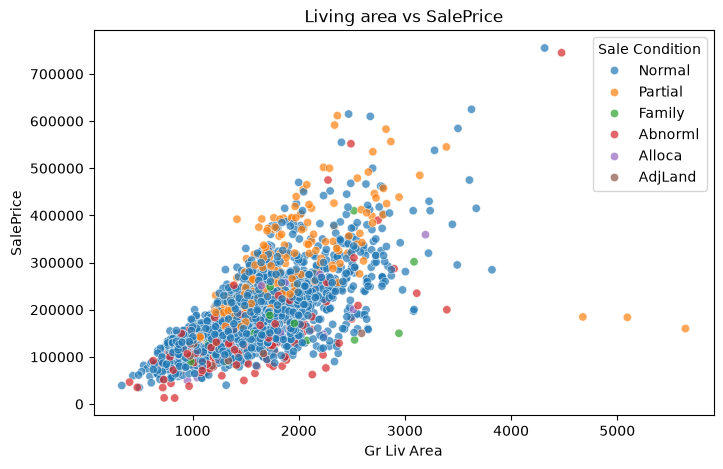

,Gr Liv Area,SalePrice,Sale Condition,Neighborhood
1498,5642,160000,Partial,Edwards
2180,5095,183850,Partial,Edwards
2181,4676,184750,Partial,Edwards
1760,4476,745000,Abnorml,NoRidge
1767,4316,755000,Normal,NoRidge


In [27]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Gr Liv Area", y=TARGET, hue="Sale Condition", alpha=0.7)
plt.title("Living area vs SalePrice")
plt.show()
display(df.nlargest(5, "Gr Liv Area")[["Gr Liv Area", TARGET, "Sale Condition", "Neighborhood"]])

**Cell 7: kya size columns overlap karte hain? (Phase 2 ka issue 7)**

In [28]:
calc = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
print("Rows where Gr Liv Area equals the sum:", (calc == df["Gr Liv Area"]).sum(), "of", len(df))

Rows where Gr Liv Area equals the sum: 2930 of 2930


**Cell 8: correlations**

In [29]:
num = df.select_dtypes("number").drop(columns=["Order", "PID"])
corr = pd.DataFrame({
    "pearson": num.corr(method="pearson")[TARGET],
    "spearman": num.corr(method="spearman")[TARGET],
}).drop(TARGET).sort_values("pearson", ascending=False)

display(corr.head(12))
display(corr.tail(5))

,pearson,spearman
Overall Qual,0.799262,0.808800
Gr Liv Area,0.706780,0.723342
Garage Cars,0.647877,0.701813
Garage Area,0.640401,0.660676
Total Bsmt SF,0.632280,0.606184
1st Flr SF,0.621676,0.581536
price_per_sqft,0.614454,0.530638
Year Built,0.558426,0.680822
Full Bath,0.545604,0.634161
Year Remod/Add,0.532974,0.601454


,pearson,spearman
Low Qual Fin SF,-0.037660,-0.071947
MS SubClass,-0.085092,0.001973
Overall Cond,-0.101697,-0.165657
Kitchen AbvGr,-0.119814,-0.141417
Enclosed Porch,-0.128787,-0.232785


**Cell 9: saal ke hisaab se price (Phase 2 ka open decision 1)**

In [30]:
print(df.groupby("Yr Sold")[TARGET].agg(["count", "median"]))
print("-"*30)
print(df.groupby("Sale Condition")["Year Built"].median())

         count    median
Yr Sold                 
2006       625  159500.0
2007       694  165125.0
2008       622  161000.0
2009       648  160850.0
2010       341  155000.0
------------------------------
Sale Condition
Abnorml    1959.0
AdjLand    1932.0
Alloca     1974.0
Family     1964.5
Normal     1971.0
Partial    2006.0
Name: Year Built, dtype: float64


## KEY FINDINGS: Sale Condition, Outliers, Correlations

### 1. Partial sales are mostly new houses

**Finding:** Houses with sale condition `Partial` sell at higher prices, but they are mostly new houses.

**Evidence:** `Partial` (245 houses) has a mean price of 273,374 and a median of 250,000. All other conditions together have a mean of about 172,349 and a median of 155,000. The median `Year Built` of `Partial` houses is 2006, compared with 1971 for `Normal` houses.

**Decision:** Keep `Partial` houses. Their higher price is explained by being new, not by a data problem. The `Year Built` feature will carry this information.

### 2. Three very large `Partial` houses have unusually low prices

**Finding:** Three houses are far larger than the rest but sold at prices that do not match their size.

**Evidence:** These houses have a living area of 5,642, 5,095 and 4,676 sq ft and sold for 160,000, 183,850 and 184,750. All three are `Partial` sales in `Edwards`, and they sit far below the trend in the scatter plot. The two other houses above 4,000 sq ft (4,476 and 4,316 sq ft, both in `NoRidge`) sold for 745,000 and 755,000, which fits the trend.

**Decision:** Remove the rows where `Sale Condition` is `Partial` and `Gr Liv Area` is above 4,000 (3 rows). Do not remove all houses above 4,000 sq ft, because that would also remove the two most expensive valid houses, which are important for our expensive-home goal. This rule will be written as one documented filter in Phase 5.

### 3. Three floor-area columns repeat `Gr Liv Area`

**Finding:** `Gr Liv Area` is the sum of `1st Flr SF`, `2nd Flr SF` and `Low Qual Fin SF`.

**Evidence:** The sum equals `Gr Liv Area` in 2,930 of 2,930 rows.

**Decision:** Keep `Gr Liv Area` and drop the three columns. In Phase 5 we may add a small feature `has_second_floor` (`2nd Flr SF` greater than 0), because it shows whether the house has more than one floor.

### 4. `Abnorml` sales sell for less, even for similar houses

**Finding:** Houses sold under `Abnorml` condition have lower prices, and part of this gap is not explained by quality or size.

**Evidence:**
- Overall median price: `Abnorml` 129,450 vs `Normal` 159,000 (about 19% lower).
- Median price per sq ft: `Abnorml` 100.9 vs `Normal` 119.3 (about 15% lower).
- Houses with `Overall Qual` between 5 and 7: `Abnorml` 137,500 (133 houses) vs `Normal` 155,000 (1,848 houses), about 11% lower.
- In the scatter plot, most `Abnorml` points lie below the main cloud at the same living area.

Note: The gap becomes smaller after comparing similar houses, so some of it comes from lower quality. The price per sq ft was used only for this analysis and will not be a model feature, because it is built from the target.

**Decision:** Treat `Abnorml` sales as non-market sales, because they break Assumption 1 in our business document. Exclude them from training and from the evaluation set. The small groups `Family`, `Alloca` and `AdjLand` (82 rows in total) are also not normal market sales and have a lower price per sq ft, so they will be excluded too. In Phase 7 we will check the effect by training with and without these rows and comparing on the same test set.

### 5. Which numeric features are linked to price

**Finding:** Quality and size features are most strongly linked to `SalePrice`.

**Evidence (Pearson correlation):** `Overall Qual` 0.80, `Gr Liv Area` 0.71, `Garage Cars` 0.65, `Garage Area` 0.64, `Total Bsmt SF` 0.63, `1st Flr SF` 0.62. `Overall Cond` (-0.10), `Kitchen AbvGr` (-0.12) and `Enclosed Porch` (-0.13) are weak and negative. `MS SubClass` (-0.09) is not meaningful, because it is a category code and not a real number.

`Year Built` has a Pearson value of 0.56 and a Spearman value of 0.68. So the link with price is increasing, but not a straight line.

**Decision:** Treat `MS SubClass` as a categorical feature. Do not judge feature importance by linear correlation alone. The negative sign of `Overall Cond` is a question to check in the next steps.

### 6. Sale year does not help

**Finding:** The median price is almost flat between 2006 and 2010.

**Evidence:** Median prices by year are 159,500, 165,125, 161,000, 160,850 and 155,000 (a range of about 6%). The year 2010 has only 341 sales, compared with 622 to 694 in the other years.

**Decision:** Do not use `Yr Sold` and `Mo Sold` as model inputs. Users ask about today's market, which is outside 2006 to 2010, and the data shows no strong time trend to learn. Keep them for analysis only.